In [12]:
import pandas as pd
import numpy as np
import openpyxl

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

data_path = Path("dataset") / "ApexPlanet_DataAnalytics_Dataset.xlsx"
if not data_path.is_file():
    data_path = Path("..") / data_path

df = pd.read_excel(data_path, engine='openpyxl')

In [13]:
# First five records
display(df.head())

# Last five records
display(df.tail())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe(include='all'))

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Unnamed: 12
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,NaN
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80,NaN
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48,NaN
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,NaN
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,NaN


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Unnamed: 12
995,ORD100997,2025-11-07,CUST6410,Customer_301,61.0,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86,NaN
996,ORD100998,2025-09-03,CUST7618,Customer_154,25.0,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25,NaN
997,ORD100999,2025-09-30,CUST9544,Customer_140,62.0,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31,NaN
998,ORD101000,2025-02-21,CUST9501,Customer_241,NaN,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09,1.0
999,ORD101001,2025-04-23,CUST2714,Customer_98,58.0,Female,Gaya,Chair,Furniture,9,22493.87,202444.83,NaN


Dataset Shape: (1000, 13)

Columns:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales', 'Unnamed: 12']
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   str    
 1   Order_Date     1000 non-null   str    
 2   Customer_ID    1000 non-null   str    
 3   Customer_Name  1000 non-null   str    
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   str    
 6   City           987 non-null    str    
 7   Product        1000 non-null   str    
 8   Category       1000 non-null   str    
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
 12  Unnamed: 12    27 non-null     float64
dtypes: float64(4), int64(1), str(8)
memory us

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Unnamed: 12
count,1000,1000,1000,1000,980.000000,1000,987,1000,1000,1000.000000,1000.000000,1000.000000,27.0
unique,992,342,947,425,NaN,2,8,6,5,NaN,NaN,NaN,NaN
top,ORD100050,2025-04-16,CUST2515,Customer_359,NaN,Male,Patna,Mobile,Electronics,NaN,NaN,NaN,NaN
freq,9,10,3,8,NaN,511,135,184,354,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,41.360204,NaN,NaN,NaN,NaN,5.435000,25486.783410,139399.439650,1.0
std,NaN,NaN,NaN,NaN,13.822597,NaN,NaN,NaN,NaN,2.838632,14179.402361,114100.051546,0.0
min,NaN,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,1.000000,145.780000,437.340000,1.0
25%,NaN,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,3.000000,13895.722500,47066.632500,1.0
50%,NaN,NaN,NaN,NaN,41.000000,NaN,NaN,NaN,NaN,5.000000,25398.740000,108594.025000,1.0
75%,NaN,NaN,NaN,NaN,54.000000,NaN,NaN,NaN,NaN,8.000000,37512.382500,203722.882500,1.0


In [14]:
for col in df.columns:

    print("\nColumn:", col)

    print("Unique Values:", df[col].nunique())

    print("Missing Values:", df[col].isnull().sum())

    print("Sample Values:")
    print(df[col].unique()[:10])

    print("-" * 50)


Column: Order_ID
Unique Values: 992
Missing Values: 0
Sample Values:
<StringArray>
['ORD100002', 'ORD100003', 'ORD100004', 'ORD100005', 'ORD100006', 'ORD100007',
 'ORD100008', 'ORD100009', 'ORD100010', 'ORD100011']
Length: 10, dtype: str
--------------------------------------------------

Column: Order_Date
Unique Values: 342
Missing Values: 0
Sample Values:
<StringArray>
['2025-02-25', '2025-10-14', '2025-05-13', '2025-12-02', '2025-11-20',
 '2025-12-31', '2025-12-05', '2025-11-21', '2025-04-16', '2025-05-05']
Length: 10, dtype: str
--------------------------------------------------

Column: Customer_ID
Unique Values: 947
Missing Values: 0
Sample Values:
<StringArray>
['CUST5529', 'CUST3127', 'CUST8887', 'CUST2515', 'CUST4796', 'CUST3952',
 'CUST1758', 'CUST9622', 'CUST9770', 'CUST1312']
Length: 10, dtype: str
--------------------------------------------------

Column: Customer_Name
Unique Values: 425
Missing Values: 0
Sample Values:
<StringArray>
['Customer_227', 'Customer_182', 'Cu

In [15]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing)

,Missing Values,Percentage
Order_ID,0,0.0
Order_Date,0,0.0
Customer_ID,0,0.0
Customer_Name,0,0.0
Age,20,2.0
Gender,0,0.0
City,13,1.3
Product,0,0.0
Category,0,0.0
Quantity,0,0.0


In [16]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df['Order_ID'].duplicated().sum())

display(
    df[df['Order_ID'].duplicated(keep=False)]
)

Duplicate Rows: 0
Duplicate Order IDs: 8


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Unnamed: 12
48,ORD100050,2025-10-03,CUST5523,Customer_432,NaN,Male,Pune,Chair,Furniture,9,30834.87,277513.83,1.0
118,ORD100050,2025-01-22,CUST3194,Customer_114,34.0,Male,Kolkata,Book,Education,2,25795.55,51591.10,NaN
238,ORD100050,2025-03-01,CUST8467,Customer_104,23.0,Male,Bengaluru,Book,Education,3,2860.83,8582.49,NaN
358,ORD100050,2025-02-11,CUST6467,Customer_181,24.0,Female,Pune,Rice,Grocery,7,45480.39,318362.73,NaN
478,ORD100050,2025-11-22,CUST8225,Customer_468,64.0,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72,NaN
598,ORD100050,2025-02-21,CUST8859,Customer_53,NaN,Male,NaN,Laptop,Electronics,7,20144.84,141013.88,1.0
718,ORD100050,2025-11-06,CUST7824,Customer_190,31.0,Female,Mumbai,Rice,Grocery,4,42642.59,170570.36,NaN
838,ORD100050,2025-08-03,CUST5585,Customer_289,35.0,Male,Kolkata,Chair,Furniture,9,28747.47,258727.23,NaN
958,ORD100050,2025-02-09,CUST7188,Customer_89,62.0,Male,Bengaluru,Mobile,Electronics,1,34619.77,34619.77,NaN


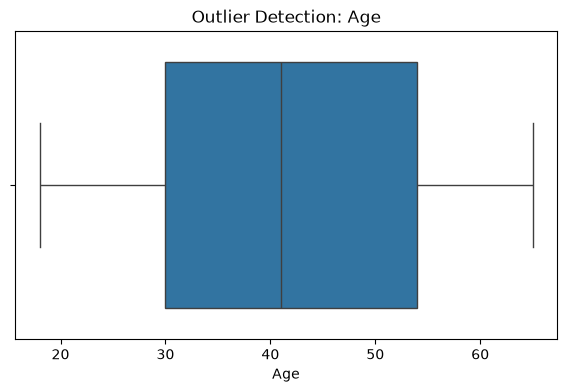

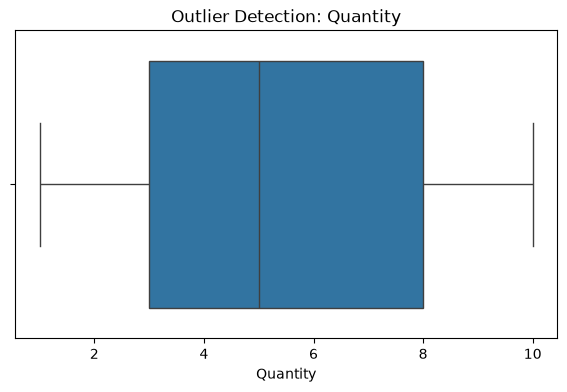

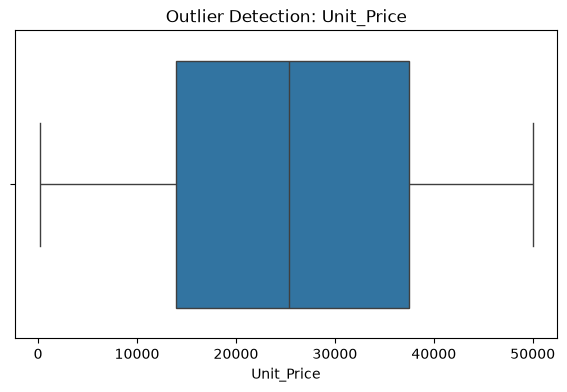

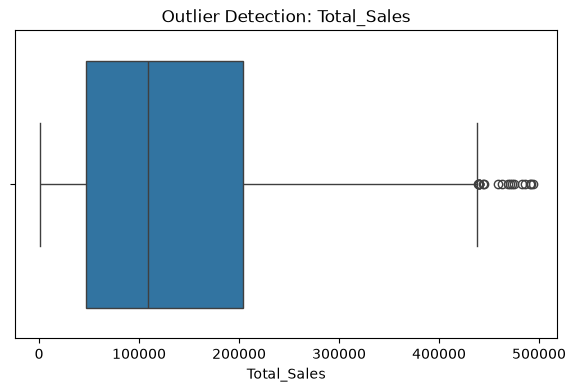

In [17]:
numerical_columns = [
    'Age',
    'Quantity',
    'Unit_Price',
    'Total_Sales'
]

for col in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[col])

    plt.title(f'Outlier Detection: {col}')

    plt.show()

In [18]:
df['Calculated_Sales'] = (
    df['Quantity'] * df['Unit_Price']
)

df['Sales_Mismatch'] = (
    abs(df['Total_Sales'] - df['Calculated_Sales']) > 0.01
)

print("Sales Mismatches:",
      df['Sales_Mismatch'].sum())

Sales Mismatches: 0


In [19]:
df_clean = df.copy()
df_clean['Age'] = df_clean['Age'].fillna(
    df_clean['Age'].median()
)
df_clean['City'] = df_clean['City'].fillna('Unknown')
df_clean['Order_Date'] = pd.to_datetime(
    df_clean['Order_Date'],
    errors='coerce'
)


In [20]:
categorical_columns = [
    'Gender',
    'City',
    'Product',
    'Category'
]

for col in categorical_columns:

    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.title()
    )

In [21]:
print("Missing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Missing Values:
Order_ID              0
Order_Date            0
Customer_ID           0
Customer_Name         0
Age                   0
Gender                0
City                  0
Product               0
Category              0
Quantity              0
Unit_Price            0
Total_Sales           0
Unnamed: 12         973
Calculated_Sales      0
Sales_Mismatch        0
dtype: int64

Duplicate Rows:
0

Data Types:
Order_ID                       str
Order_Date          datetime64[us]
Customer_ID                    str
Customer_Name                  str
Age                        float64
Gender                         str
City                           str
Product                        str
Category                       str
Quantity                     int64
Unit_Price                 float64
Total_Sales                float64
Unnamed: 12                float64
Calculated_Sales           float64
Sales_Mismatch                bool
dtype: object


In [22]:
df_clean['Year'] = df_clean['Order_Date'].dt.year

df_clean['Month'] = df_clean['Order_Date'].dt.month

df_clean['Month_Name'] = df_clean['Order_Date'].dt.month_name()

df_clean['Day'] = df_clean['Order_Date'].dt.day

df_clean['Day_Name'] = df_clean['Order_Date'].dt.day_name()

In [23]:
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],

    bins=[0, 18, 30, 45, 60, 100],

    labels=[
        'Teenager',
        'Young Adult',
        'Adult',
        'Middle Aged',
        'Senior'
    ]
)

In [24]:
df_clean['Sales_Category'] = pd.cut(
    df_clean['Total_Sales'],

    bins=[0, 50000, 150000, 300000, float('inf')],

    labels=[
        'Low',
        'Medium',
        'High',
        'Very High'
    ]
)

In [25]:
df_clean['Total_Revenue'] = (
    df_clean['Quantity'] * df_clean['Unit_Price']
)

In [26]:
display(df_clean.head())

print(df_clean.columns.tolist())

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,...,Calculated_Sales,Sales_Mismatch,Year,Month,Month_Name,Day,Day_Name,Age_Group,Sales_Category,Total_Revenue
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,...,19808.39,False,2025,2,February,25,Tuesday,Young Adult,Low,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,...,139530.80,False,2025,10,October,14,Tuesday,Senior,Medium,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,...,299928.48,False,2025,5,May,13,Tuesday,Senior,High,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,...,256872.24,False,2025,12,December,2,Tuesday,Senior,High,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,...,140365.90,False,2025,11,November,20,Thursday,Adult,Medium,140365.90


['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales', 'Unnamed: 12', 'Calculated_Sales', 'Sales_Mismatch', 'Year', 'Month', 'Month_Name', 'Day', 'Day_Name', 'Age_Group', 'Sales_Category', 'Total_Revenue']


In [27]:
print("FINAL DATASET VALIDATION")

print("Shape:", df_clean.shape)

print("Missing Values:")
print(df_clean.isnull().sum())

print("Duplicate Rows:", df_clean.duplicated().sum())

print("Data Types:")
print(df_clean.dtypes)

display(df_clean.describe(include='all'))

FINAL DATASET VALIDATION
Shape: (1000, 23)
Missing Values:
Order_ID              0
Order_Date            0
Customer_ID           0
Customer_Name         0
Age                   0
Gender                0
City                  0
Product               0
Category              0
Quantity              0
Unit_Price            0
Total_Sales           0
Unnamed: 12         973
Calculated_Sales      0
Sales_Mismatch        0
Year                  0
Month                 0
Month_Name            0
Day                   0
Day_Name              0
Age_Group             0
Sales_Category        0
Total_Revenue         0
dtype: int64
Duplicate Rows: 0
Data Types:
Order_ID                       str
Order_Date          datetime64[us]
Customer_ID                    str
Customer_Name                  str
Age                        float64
Gender                         str
City                           str
Product                        str
Category                       str
Quantity                     in

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,...,Calculated_Sales,Sales_Mismatch,Year,Month,Month_Name,Day,Day_Name,Age_Group,Sales_Category,Total_Revenue
count,1000,1000,1000,1000,1000.000000,1000,1000,1000,1000,1000.000000,...,1000.000000,1000,1000.000000,1000.000000,1000,1000.000000,1000,1000,1000,1000.000000
unique,992,NaN,947,425,NaN,2,9,6,5,NaN,...,NaN,1,NaN,NaN,12,NaN,7,5,4,NaN
top,ORD100050,NaN,CUST2515,Customer_359,NaN,Male,Patna,Mobile,Electronics,NaN,...,NaN,False,NaN,NaN,December,NaN,Sunday,Adult,Medium,NaN
freq,9,NaN,3,8,NaN,511,135,184,354,NaN,...,NaN,1000,NaN,NaN,98,NaN,153,332,359,NaN
mean,NaN,2025-07-03 11:19:40.800000,NaN,NaN,41.353000,NaN,NaN,NaN,NaN,5.435000,...,139399.439650,NaN,2025.005000,6.518000,NaN,15.605000,NaN,NaN,NaN,139399.439650
min,NaN,2025-01-01 00:00:00,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,1.000000,...,437.340000,NaN,2025.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,437.340000
25%,NaN,2025-03-30 18:00:00,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,3.000000,...,47066.632500,NaN,2025.000000,3.000000,NaN,8.000000,NaN,NaN,NaN,47066.632500
50%,NaN,2025-07-01 00:00:00,NaN,NaN,41.000000,NaN,NaN,NaN,NaN,5.000000,...,108594.025000,NaN,2025.000000,6.000000,NaN,16.000000,NaN,NaN,NaN,108594.025000
75%,NaN,2025-10-07 06:00:00,NaN,NaN,53.000000,NaN,NaN,NaN,NaN,8.000000,...,203722.882500,NaN,2025.000000,10.000000,NaN,23.000000,NaN,NaN,NaN,203722.882500
max,NaN,2026-01-01 00:00:00,NaN,NaN,65.000000,NaN,NaN,NaN,NaN,10.000000,...,493677.500000,NaN,2026.000000,12.000000,NaN,31.000000,NaN,NaN,NaN,493677.500000


In [32]:
project_dir = Path(".") if Path("dataset").is_dir() else Path("..")
output_dir = project_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_dir / "ApexPlanet_Cleaned_Dataset.csv", index=False)
df_clean.to_excel(output_dir / "ApexPlanet_Cleaned_Dataset.xlsx", index=False)